# Demo 3: A World Model That Learned Physics From Video (Meta V-JEPA 2)

**From Equation to World Models: AI and the Simulation of Physics** · SIET talk

Demos 1 and 2 still needed **equations** or **simulations**. A **world model** skips both: it watches millions of hours of ordinary video and learns to **predict what happens next**.

**V-JEPA 2** (Meta, 2025, open weights on Hugging Face) is trained with a simple self-supervised game:

> Hide part of a video. From the visible part, predict the **abstract representation** (not the pixels) of the hidden part.

$$\hat{\mathbf s}_{\text{future}} = P_\phi\big(E_\theta(\text{video}_{\text{past}})\big),\qquad L = \big\|\hat{\mathbf s}_{\text{future}} - E_{\bar\theta}(\text{video})_{\text{future}}\big\|_1$$

Everything here is tensor algebra again. A 16-frame clip becomes a tensor of shape `(1, 16, 3, 256, 256)`. It is cut into $2\times16\times16$ "tubelets", giving **2,048 tokens**, each a **1,024-dimensional vector**, processed by a 300-million-parameter Vision Transformer.

In this notebook:
1. **Look inside:** what the model's vectors "see" in a video.
2. **Intuitive physics test:** we show it physically possible and impossible videos and measure its **surprise** (prediction error), much like tests of infant cognition.
3. **Action recognition:** a version fine-tuned to name what is happening in a clip, including your own phone video.

> **Before the talk:** run `prefetch_models.py` once with internet access so both models (about 2.5 GB) are cached and the demo works offline.

In [2]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # let Apple-GPU fall back to CPU for any missing op
import time, math
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoVideoProcessor, AutoModel, AutoModelForVideoClassification

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110})
print("device:", device)

WORLD_MODEL_ID = "facebook/vjepa2-vitl-fpc64-256"          # self-supervised world model (encoder + predictor)
CLASSIFIER_ID = "facebook/vjepa2-vitl-fpc16-256-ssv2"       # fine-tuned on Something-Something-v2 actions

/Users/astrobalaji/Documents/SIET/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps


In [3]:
t0 = time.time()
processor = AutoVideoProcessor.from_pretrained(WORLD_MODEL_ID)
wm = AutoModel.from_pretrained(WORLD_MODEL_ID).to(device).eval()
print(f"loaded in {time.time() - t0:.0f} s  |  parameters: {sum(p.numel() for p in wm.parameters()) / 1e6:.0f} M")

cfg = wm.config
PATCH = getattr(cfg, "patch_size", 16)
TUBELET = getattr(cfg, "tubelet_size", 2)
CROP = getattr(cfg, "crop_size", 256)
GRID = CROP // PATCH                 # 16 x 16 patches per frame
TPF = GRID * GRID                    # tokens per temporal slice
print(f"patch {PATCH}px, tubelet {TUBELET} frames, grid {GRID}x{GRID} = {TPF} tokens per time step")

def run_encoder(pix):
    # pixel tensor (1, T, 3, 256, 256) -> token vectors (1, n_tokens, 1024)
    try:
        return wm.encoder(pixel_values_videos=pix).last_hidden_state
    except TypeError:
        return wm(pixel_values_videos=pix, skip_predictor=True).last_hidden_state

def run_predictor(pix, ctx_tokens, n_ctx, n_all):
    # predict the representation of tokens n_ctx..n_all from the context tokens only
    cmask = [torch.arange(n_ctx, device=device).unsqueeze(0)]
    tmask = [torch.arange(n_ctx, n_all, device=device).unsqueeze(0)]
    enc_in = torch.cat([ctx_tokens, ctx_tokens.new_zeros(1, n_all - n_ctx, ctx_tokens.shape[-1])], 1)
    try:
        return wm.predictor(encoder_hidden_states=enc_in, context_mask=cmask, target_mask=tmask).last_hidden_state
    except TypeError:
        print("(fallback: using model.forward with masks; the encoder then also sees the future frames)")
        return wm(pixel_values_videos=pix, context_mask=cmask, target_mask=tmask).predictor_output.last_hidden_state

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 587/587 [00:00<00:00, 7434.87it/s]


loaded in 3 s  |  parameters: 326 M
patch 16px, tubelet 2 frames, grid 16x16 = 256 tokens per time step


---
## Making physics videos

We draw simple 16-frame videos of a ball, with a lab bench, a floor and some shadows. Some scenes follow the laws of physics and some **break** them. The first 8 frames (the "past") are identical within each pair. The violation happens only in the last 8 frames (the "future").

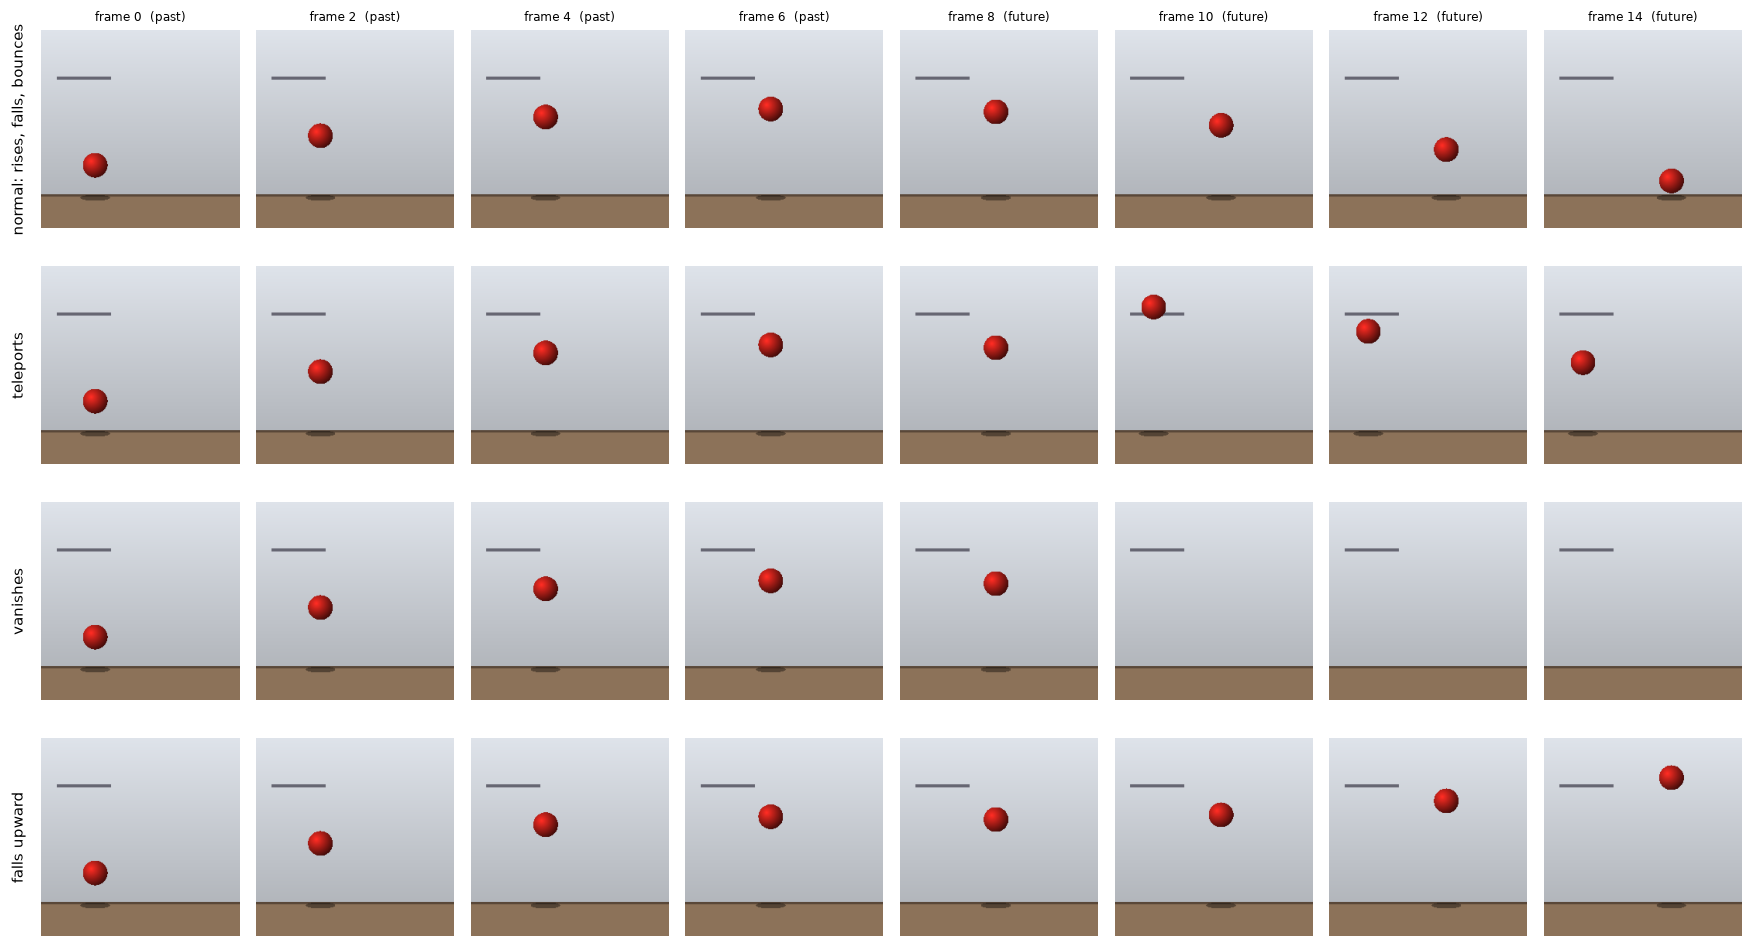

In [4]:
H = W = 256
N_FRAMES = 16
FLOOR = 212

def background():
    img = np.zeros((H, W, 3), np.float32)
    g = np.linspace(0.92, 0.70, H)[:, None]
    img[:] = np.stack([g * 0.95, g * 0.97, g], -1)             # soft wall gradient
    img[FLOOR:] = [0.55, 0.45, 0.35]                           # wooden floor
    img[FLOOR:FLOOR + 3] = [0.35, 0.28, 0.22]
    img[60:64, 20:90] = [0.4, 0.4, 0.45]                        # a shelf, for visual context
    return img

YY, XX = np.mgrid[0:H, 0:W]

def draw_ball(img, cx, cy, r=16, color=(0.85, 0.15, 0.12)):
    if cx is None:
        return img
    # shadow on the floor
    sh = ((XX - cx) / (r * 1.2)) ** 2 + ((YY - (FLOOR + 4)) / 4) ** 2 < 1
    img[sh] *= 0.6
    d2 = (XX - cx) ** 2 + (YY - cy) ** 2
    m = d2 < r * r
    shade = np.clip(1.2 - np.sqrt(((XX - cx + r / 3) ** 2 + (YY - cy + r / 3) ** 2)) / (1.6 * r), 0.3, 1.2)
    img[m] = (np.array(color)[None, :] * shade[m][:, None])
    return img

def ballistic_trajectory(x0, y0, vx, vy, g=500.0, restitution=0.7, r=16, fps=12, n=N_FRAMES):
    # Real physics: constant gravity, bounce off the floor with energy loss
    xs, ys = [], []
    x, y, dt = x0, y0, 1.0 / fps
    sub = 50
    for _ in range(n):
        xs.append(x); ys.append(y)
        for _ in range(sub):
            vy += g * dt / sub
            x += vx * dt / sub; y += vy * dt / sub
            if y > FLOOR - r:
                y = FLOOR - r; vy = -restitution * vy
            if x < 30 + r or x > W - 30 - r:
                vx = -vx
    return np.array(xs), np.array(ys)

def render(xs, ys):
    frames = [draw_ball(background(), cx, cy) for cx, cy in zip(xs, ys)]
    return (np.clip(np.stack(frames), 0, 1) * 255).astype(np.uint8)       # (T, H, W, 3)

def make_scenarios(seed=0):
    # A ball is thrown up and to the right. It rises during the "past" frames and should
    # come back down during the "future" frames.
    rng = np.random.default_rng(seed)
    x0 = rng.uniform(50, 80); y0 = rng.uniform(170, 185)
    vx = rng.uniform(80, 120); vy = -rng.uniform(270, 310)
    xs, ys = ballistic_trajectory(x0, y0, vx, vy)
    xs, ys = list(xs), list(ys)
    half = N_FRAMES // 2
    s = {"normal: rises, falls, bounces": (xs, ys)}
    # 1) teleportation: from frame 9 the ball jumps to a different place
    xt = list(xs); yt = list(ys)
    for i in range(half + 1, N_FRAMES):
        xt[i] = max(50, xs[i] - 120); yt[i] = ys[i] - 70
    s["teleports"] = (xt, yt)
    # 2) object permanence: the ball simply vanishes
    xv = list(xs); yv = list(ys)
    for i in range(half + 1, N_FRAMES):
        xv[i] = None; yv[i] = None
    s["vanishes"] = (xv, yv)
    # 3) anti-gravity: instead of falling, the ball accelerates upward
    xa = list(xs); ya = list(ys)
    for i in range(half + 1, N_FRAMES):
        xa[i] = xs[half] + (xs[half] - xs[half - 1]) * (i - half)
        ya[i] = ys[half] - 1.5 * (i - half) ** 2
    s["falls upward"] = (xa, ya)
    return {k: render(*v) for k, v in s.items()}

videos = make_scenarios(seed=0)
fig, axes = plt.subplots(len(videos), 8, figsize=(16, 2.2 * len(videos)))
for r, (name, vid) in enumerate(videos.items()):
    for c, t in enumerate(range(0, N_FRAMES, 2)):
        axes[r, c].imshow(vid[t]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(f"frame {t}" + ("  (past)" if t < 8 else "  (future)"), fontsize=8)
    axes[r, 0].text(-20, H / 2, name, rotation=90, va="center", ha="right", fontsize=10)
plt.tight_layout(); plt.show()

---
## 1. Look inside: what do the vectors see?

Each 16×16-pixel patch becomes a 1,024-dimensional vector. We compress these vectors to 3 numbers with **PCA** (principal component analysis, the eigenvectors of the covariance matrix) and show those 3 numbers as red, green and blue.

Nobody told the model what a "ball" or a "floor" is, yet the vectors separate them.

input tensor: (1, 16, 3, 256, 256) ->  tokens: (1, 2048, 1024)


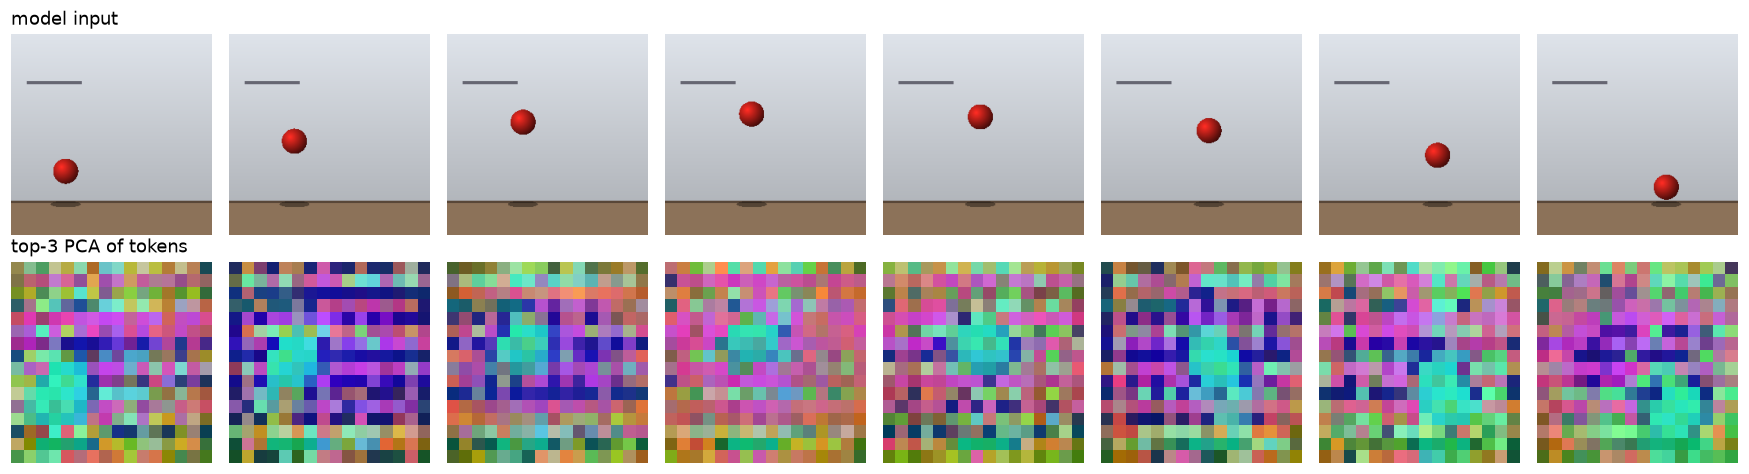

In [5]:
@torch.no_grad()
def encode(video_uint8):
    # video (T,H,W,3) uint8 -> encoder tokens (1, n_tokens, 1024)
    v = torch.from_numpy(video_uint8).permute(0, 3, 1, 2)                 # T x C x H x W
    pix = processor(v, return_tensors="pt")["pixel_values_videos"].to(device)
    return pix, run_encoder(pix)

pix, feats = encode(videos["normal: rises, falls, bounces"])
print("input tensor:", tuple(pix.shape), "->  tokens:", tuple(feats.shape))

f = feats[0].float().cpu()                                      # (2048, 1024)
f = f - f.mean(0)
U, S, V = torch.pca_lowrank(f, q=3)
rgb = (f @ V[:, :3])
rgb = (rgb - rgb.min(0).values) / (rgb.max(0).values - rgb.min(0).values)
rgb = rgb.view(-1, GRID, GRID, 3)                               # (time slices, 16, 16, 3)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    axes[0, i].imshow(videos["normal: rises, falls, bounces"][2 * i]); axes[0, i].axis("off")
    axes[1, i].imshow(rgb[i].numpy(), interpolation="nearest"); axes[1, i].axis("off")
axes[0, 0].set_title("model input", loc="left"); axes[1, 0].set_title("top-3 PCA of tokens", loc="left")
plt.tight_layout(); plt.show()

---
## 2. Intuitive physics: measuring "surprise"

1. The **encoder** sees **only the first 8 frames** (the past).
2. The **predictor** guesses the representation of the **last 8 frames**.
3. We encode what *actually* happened and measure the prediction error:

$$\text{surprise}(t) = \frac{1}{N}\sum_{\text{patches}}\big\|\hat{\mathbf s}_{t} - \mathbf s_{t}\big\|_1$$

If the model has learned something like "objects fall, objects don't teleport, objects don't vanish", then **impossible videos should be more surprising**. The same idea is used to test infants: they look longer at impossible events.

*Results on cartoon videos can be noisy, since the model was trained on real-world footage. We therefore average over several random throws.*

In [6]:
@torch.no_grad()
def surprise(video_uint8):
    v = torch.from_numpy(video_uint8).permute(0, 3, 1, 2)
    pix = processor(v, return_tensors="pt")["pixel_values_videos"].to(device)
    T = pix.shape[1]; Tc = T // 2
    n_ctx, n_all = (Tc // TUBELET) * TPF, (T // TUBELET) * TPF

    target = run_encoder(pix)[:, n_ctx:]                     # what really happened
    ctx = run_encoder(pix[:, :Tc])                           # the encoder sees ONLY the past 8 frames
    pred = run_predictor(pix, ctx, n_ctx, n_all)             # the predictor imagines the future

    D = pred.shape[-1]
    err = (F.layer_norm(pred.float(), (D,)) - F.layer_norm(target.float(), (D,))).abs().mean(-1)[0]   # per token
    err = err.view(-1, GRID, GRID).cpu()                                                   # (future slices, 16, 16)
    return err.mean((1, 2)).numpy(), err.numpy()

t0 = time.time()
curve, emap = surprise(videos["normal: rises, falls, bounces"])
print(f"one surprise evaluation: {time.time() - t0:.1f} s   surprise per future time-step: {np.round(curve, 3)}")

one surprise evaluation: 1.5 s   surprise per future time-step: [0.607 0.607 0.627 0.634]


evaluated 16 videos in 18 s


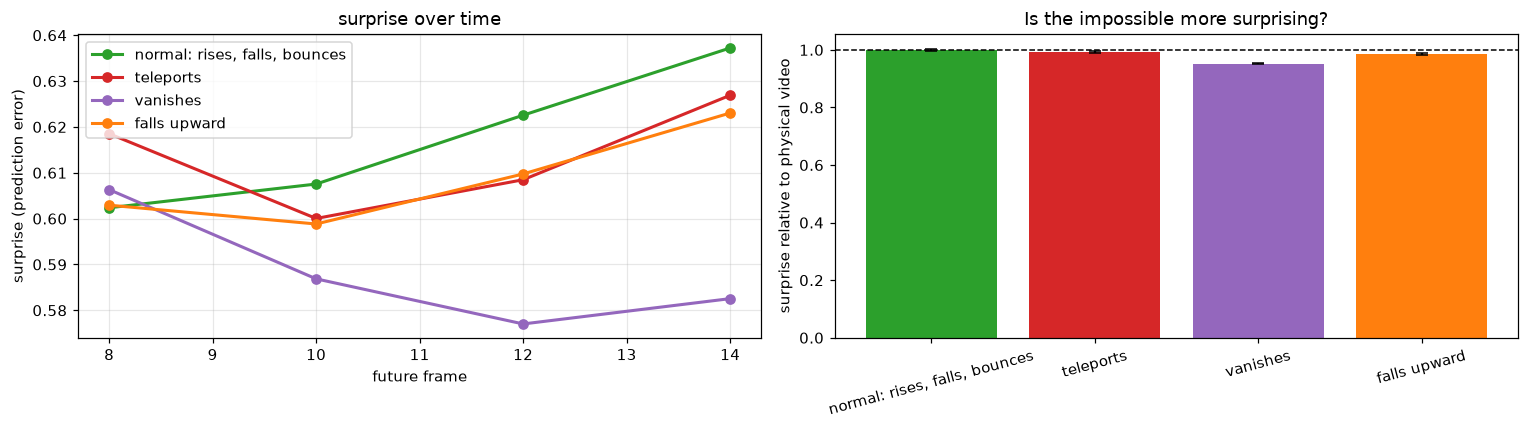

normal: rises, falls, bounces  1.00x
teleports                   0.99x
vanishes                    0.95x
falls upward                0.99x


In [7]:
N_THROWS = 4          # random throws per scenario (more = smoother, slower)
results, maps = {}, {}
t0 = time.time()
for seed in range(N_THROWS):
    for name, vid in make_scenarios(seed).items():
        c, m = surprise(vid)
        results.setdefault(name, []).append(c)
        if seed == 0: maps[name] = m
print(f"evaluated {N_THROWS * len(results)} videos in {time.time() - t0:.0f} s")

names = list(results)
mean_curves = {k: np.mean(v, 0) for k, v in results.items()}
base = mean_curves[names[0]].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
colors = ["tab:green", "tab:red", "tab:purple", "tab:orange"]
for (k, c), col in zip(mean_curves.items(), colors):
    ax[0].plot(np.arange(len(c)) * TUBELET + N_FRAMES // 2, c, "o-", color=col, lw=2, label=k)
ax[0].set_xlabel("future frame"); ax[0].set_ylabel("surprise (prediction error)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title("surprise over time")
vals = [np.mean(results[k]) / base for k in names]
errs = [np.std(np.mean(results[k], 1)) / base for k in names]
ax[1].bar(range(len(names)), vals, yerr=errs, color=colors, capsize=4)
ax[1].axhline(1.0, color="k", ls="--", lw=1)
ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(names, rotation=15)
ax[1].set_ylabel("surprise relative to physical video"); ax[1].set_title("Is the impossible more surprising?")
plt.tight_layout(); plt.show()
for k, v in zip(names, vals):
    print(f"{k:26s} {v:5.2f}x")

### Where is the model surprised?

The prediction error for each patch, over the future frames. It lights up around the place where physics was broken.

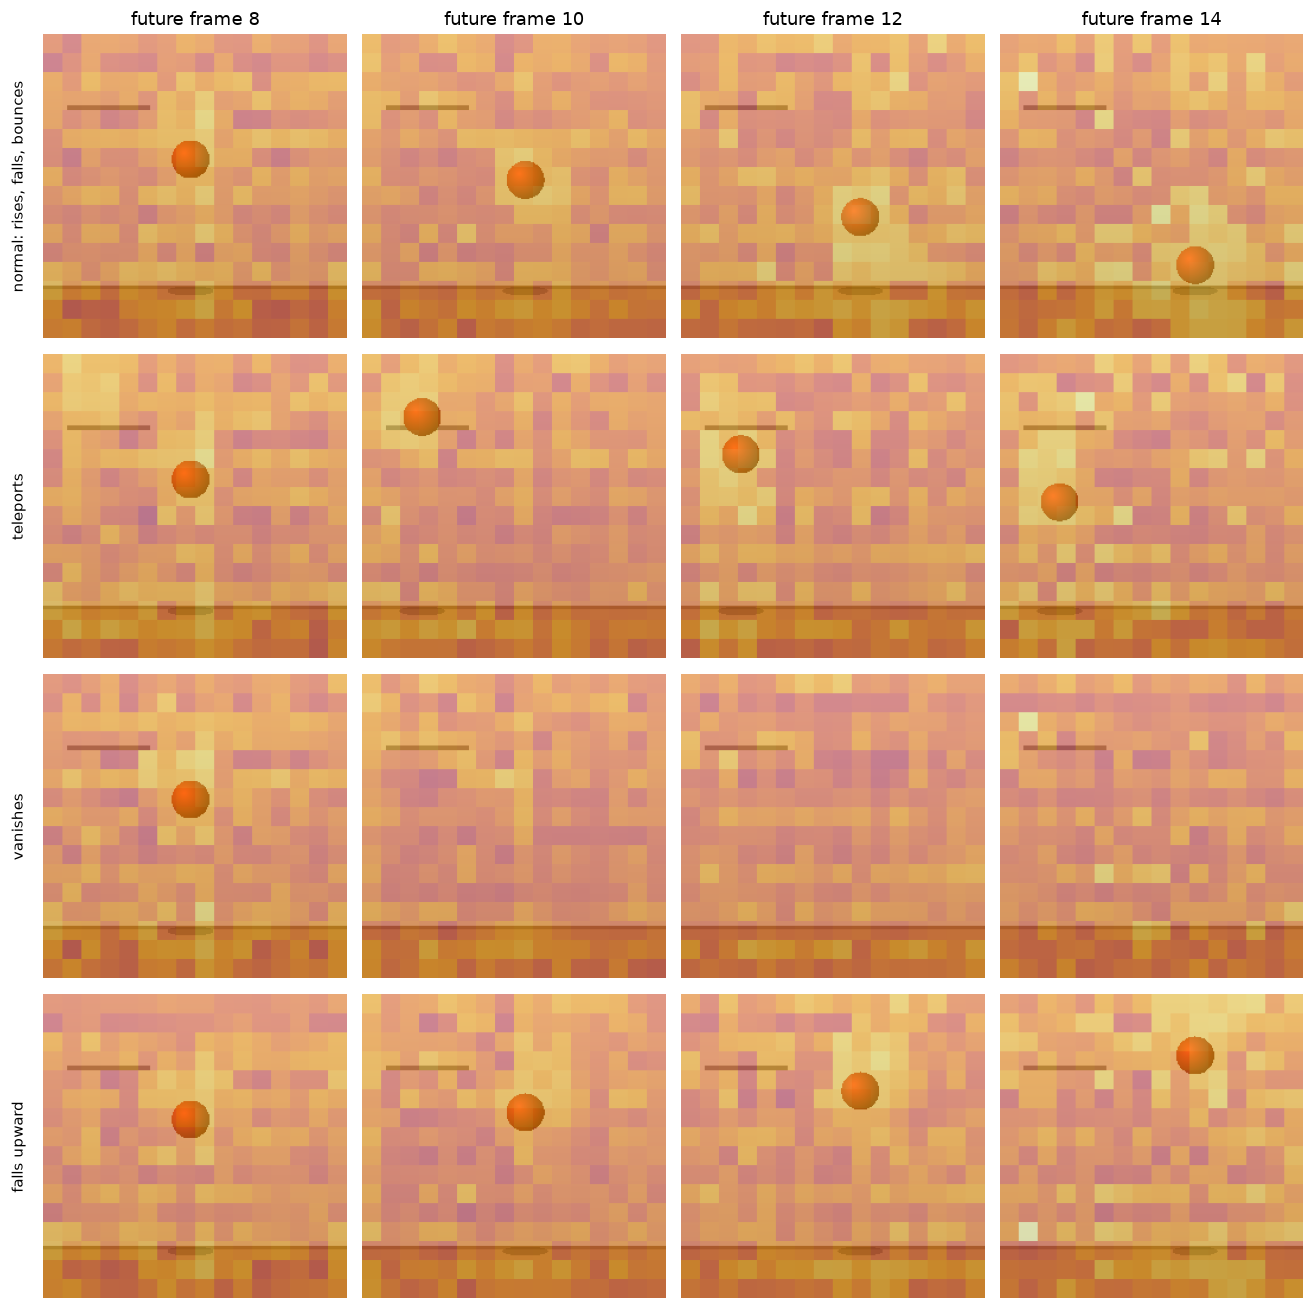

In [8]:
fig, axes = plt.subplots(len(maps), 4, figsize=(12, 3 * len(maps)))
vmax = max(m.max() for m in maps.values())
vids0 = make_scenarios(0)
for r, (name, m) in enumerate(maps.items()):
    for c in range(4):
        frame = vids0[name][N_FRAMES // 2 + TUBELET * c]
        axes[r, c].imshow(frame)
        axes[r, c].imshow(np.kron(m[c], np.ones((H // GRID, W // GRID))), cmap="inferno", alpha=0.55, vmin=0, vmax=vmax)
        axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(f"future frame {N_FRAMES // 2 + TUBELET * c}")
    axes[r, 0].text(-15, H / 2, name, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

---
## 3. Naming the physics: action recognition

The same encoder, fine-tuned on **Something-Something-v2** (220,000 clips of people doing physical things with objects, 174 classes such as *"Something falling like a rock"* or *"Pushing something so that it slightly moves"*).

In [9]:
clf_processor = AutoVideoProcessor.from_pretrained(CLASSIFIER_ID)
clf = AutoModelForVideoClassification.from_pretrained(CLASSIFIER_ID).to(device).eval()

@torch.no_grad()
def classify(video_uint8, k=5):
    v = torch.from_numpy(video_uint8).permute(0, 3, 1, 2)
    inputs = clf_processor(v, return_tensors="pt").to(device)
    probs = clf(**inputs).logits.softmax(-1)[0].float().cpu()
    top = probs.topk(k)
    return [(clf.config.id2label[int(i)], float(p)) for p, i in zip(top.values, top.indices)]

for name, vid in make_scenarios(0).items():
    print(f"\n{name}")
    for label, p in classify(vid, k=3):
        print(f"   {p * 100:5.1f}%  {label}")

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 652/652 [00:00<00:00, 7677.93it/s]



normal: rises, falls, bounces
    28.6%  Letting [something] roll along a flat surface
    19.4%  Spinning [something] so it continues spinning
     7.7%  Rolling [something] on a flat surface

teleports
    14.9%  Letting [something] roll along a flat surface
    10.6%  [Something] colliding with [something] and both are being deflected
    10.4%  Spinning [something] so it continues spinning

vanishes
    39.7%  Tilting [something] with [something] on it until it falls off
     9.7%  [Something] falling like a rock
     6.9%  Letting [something] roll down a slanted surface

falls upward
    19.6%  Letting [something] roll along a flat surface
    16.7%  Turning the camera left while filming [something]
    11.2%  Spinning [something] so it continues spinning


### Your own video (the best live demo)

Record a 2–4 second phone video: drop a ball, roll a bottle, push a cup, pour water. Save it next to this notebook as `my_video.mp4`, then run the next cell. Any format OpenCV can read will work.

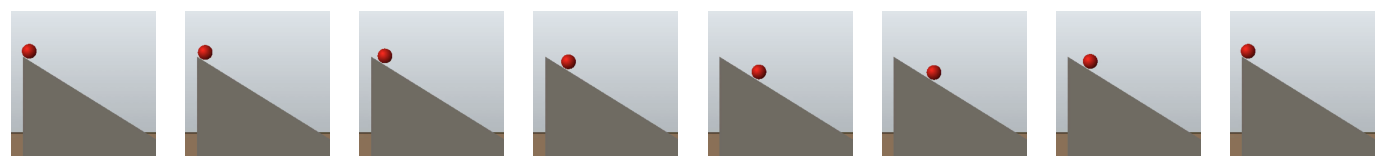

What is happening?
    25.7%  Letting [something] roll down a slanted surface
    17.2%  Tilting [something] with [something] on it slightly so it doesn't fall down
     6.4%  Letting [something] roll up a slanted surface, so it rolls back down
     5.7%  Letting [something] roll along a flat surface
     5.6%  Tilting [something] with [something] on it until it falls off

surprise over the second half: [0.639 0.613 0.618 0.63 ]  (compare with the synthetic videos above)


In [11]:
import cv2

def load_video(path, n_frames=16, size=256):
    cap = cv2.VideoCapture(path)
    frames = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    cap.release()
    if not frames:
        raise FileNotFoundError(f"could not read frames from {path}")
    idx = np.linspace(0, len(frames) - 1, n_frames).round().astype(int)
    out = []
    for i in idx:
        f = frames[i]; h, w = f.shape[:2]; s = min(h, w)
        f = f[(h - s) // 2:(h + s) // 2, (w - s) // 2:(w + s) // 2]        # centre square crop
        out.append(cv2.resize(f, (size, size), interpolation=cv2.INTER_AREA))
    return np.stack(out)

VIDEO_PATH = "videos/generated/ramp__rolls_back_uphill.mp4"
if os.path.exists(VIDEO_PATH):
    myvid = load_video(VIDEO_PATH)
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.2))
    for a, t in zip(axes, range(0, 16, 2)): a.imshow(myvid[t]); a.axis("off")
    plt.show()
    print("What is happening?")
    for label, p in classify(myvid):
        print(f"   {p * 100:5.1f}%  {label}")
    curve, _ = surprise(myvid)
    print("\nsurprise over the second half:", np.round(curve, 3), " (compare with the synthetic videos above)")
else:
    print(f"Put a video at {os.path.abspath(VIDEO_PATH)} and re-run this cell.")

### Takeaways

* A **world model** learns an internal simulator of the world *from observation*, without being given equations.
* Under the hood it is the same mathematics: video → tensor → token vectors → attention (tensor contractions) → predicted vectors.
* Its prediction error works like **surprise**, which lets us probe whether it has learned intuitive physics (object permanence, continuity, gravity).
* **Open questions:** Does it understand physics or only mimic it? Does it conserve energy? Can it extrapolate? Can we pull equations back *out* of it?

**The journey:** Equation (Newton) → Physics-informed networks (Demo 1) → Neural operators (Demo 2) → World models learned from video (Demo 3).